# Parte 2: Modelo — riesgo coronario a 10 años (Caso 5)

**EP5 — Gestión de Proyectos de Datos (SCY1102).**

Entrada: `framingham_cohorte.csv`, la salida de la Parte 1.
Salida: `modelo_chd10a.pkl` (para la Parte 3), `experimentos.csv` (registro de resultados parciales) y las figuras de evaluación.

## Carpeta de trabajo
Se monta Drive y se trabaja en la carpeta del proyecto, así que todo lo que se guarde queda ahí. Los insumos se leen de `datos/` y lo que genera el cuaderno se guarda en `resultados/`.

In [1]:
import os

CARPETA = "/content/drive/MyDrive/Evalucion 3 y Examen"   # ruta del acceso directo en Mi unidad

try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(CARPETA)
except ModuleNotFoundError:
    pass   # fuera de Colab se usa la carpeta actual

os.makedirs("datos", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

print("Carpeta:", os.getcwd())
for f in ['datos/framingham_cohorte.csv']:
    print(f, "presente:", os.path.exists(f))

Mounted at /content/drive
Carpeta: /content/drive/.shortcut-targets-by-id/1Y-XrKLmj3y7vuHBzmQH9X-DvE-h6v7OV/Evalucion 3 y Examen
datos/framingham_cohorte.csv presente: True


## Cargar los datos

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("datos/framingham_cohorte.csv")

CONT = ["AGE", "SYSBP", "DIABP", "TOTCHOL", "GLUCOSE", "BMI", "HEARTRTE", "CIGPDAY"]
BIN = ["SEX", "CURSMOKE", "DIABETES", "BPMEDS"]
PRED = CONT + BIN

X = df[PRED]
y = df["chd_10a"]

print(df.shape)
print(f"Casos: {y.sum()} de {len(y)} ({y.mean():.1%})")

(4224, 14)
Casos: 379 de 4224 (9.0%)


## Partición entrenamiento / prueba
80/20 estratificada, para que ambos conjuntos tengan la misma proporción de casos. Cada fila es una persona distinta (la Parte 1 verificó 0 IDs repetidos), así que la partición separa personas. El conjunto de prueba se usa una sola vez, al final, con el modelo ya elegido.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Entrenamiento: {len(X_train)} personas, {y_train.sum()} casos ({y_train.mean():.1%})")
print(f"Prueba:        {len(X_test)} personas, {y_test.sum()} casos ({y_test.mean():.1%})")

Entrenamiento: 3379 personas, 303 casos (9.0%)
Prueba:        845 personas, 76 casos (9.0%)


## Preprocesamiento
Es el imputador que definió la Parte 1 (mediana en continuas, moda en binarias), más escalado de las continuas. Va dentro del Pipeline, así que las medianas y el escalado se calculan solo con los datos de entrenamiento de cada pliegue, sin fuga hacia la validación.

No hay variables categóricas con más de dos niveles, así que no se necesita one-hot encoding.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

def preprocesador():
    return ColumnTransformer([
        ("cont", Pipeline([("imp", SimpleImputer(strategy="median")),
                           ("esc", StandardScaler())]), CONT),
        ("bin", SimpleImputer(strategy="most_frequent"), BIN),
    ])

## Métricas y registro de experimentos
Con 9 % de casos, el accuracy no sirve: un modelo que diga "nadie se enferma" acierta 91 %. Se usan:

- **ROC-AUC**: qué tan bien ordena a las personas por riesgo. Es la métrica para elegir modelo.
- **PR-AUC**: lo mismo, pero enfocado en los casos positivos. Su valor de referencia es la prevalencia (0,09), no 0,5.
- **Recall**: de los que se enferman, cuántos detecta. Es la prioridad en tamizaje.
- **Precisión y F1**.
- **Brier**: error de la probabilidad estimada. Sirve para saber si un "20 % de riesgo" significa de verdad 20 %.

Todo se evalúa con validación cruzada de 5 pliegues sobre el entrenamiento, y cada experimento queda registrado en una tabla.

In [5]:
from datetime import date
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

METRICAS = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "Recall": "recall",
            "Precisión": "precision", "F1": "f1", "Brier": "neg_brier_score"}

registro = []

def evaluar(version, nombre, modelo, descripcion):
    pipe = Pipeline([("pre", preprocesador()), ("modelo", modelo)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=METRICAS)
    fila = {"Versión": version, "Modelo": nombre, "Configuración": descripcion}
    for m in METRICAS:
        v = r[f"test_{m}"].mean()
        fila[m] = round(-v if m == "Brier" else v, 3)
    fila["Fecha"] = date.today().isoformat()
    registro.append(fila)
    return fila

def tabla(version=None):
    t = pd.DataFrame(registro)
    return t if version is None else t[t["Versión"] == version]

## v1 — Modelos base
Los tres modelos con su configuración por defecto. Como hay pocos casos, se les compensa el desbalance: `class_weight` en regresión logística y random forest, y `scale_pos_weight` en XGBoost.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

peso = (y_train == 0).sum() / (y_train == 1).sum()   # ~10 sanos por cada caso

evaluar("v1", "Regresión logística", LogisticRegression(class_weight="balanced", max_iter=1000),
        "class_weight=balanced")
evaluar("v1", "Random forest", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
        random_state=42, n_jobs=-1), "300 árboles, por defecto")
evaluar("v1", "XGBoost", XGBClassifier(scale_pos_weight=peso, eval_metric="logloss", random_state=42),
        "por defecto")

tabla("v1")

,Versión,Modelo,Configuración,ROC-AUC,PR-AUC,Recall,Precisión,F1,Brier,Fecha
0,v1,Regresión logística,class_weight=balanced,0.730,0.223,0.673,0.161,0.260,0.209,2026-11-14
1,v1,Random forest,"300 árboles, por defecto",0.682,0.184,0.007,0.133,0.013,0.079,2026-11-14
2,v1,XGBoost,por defecto,0.629,0.146,0.083,0.147,0.105,0.099,2026-11-14


Random forest y XGBoost por defecto sobreajustan: árboles profundos que memorizan el entrenamiento y casi nunca predicen un caso (recall cercano a 0), a pesar de la compensación de clases. La regresión logística ordena mejor desde el inicio.

## v2 — Ajuste de hiperparámetros
Búsqueda en grilla con la misma validación cruzada, optimizando ROC-AUC. En los árboles se busca limitar la profundidad y el tamaño mínimo de las hojas, que es lo que controla el sobreajuste.

In [7]:
from sklearn.model_selection import GridSearchCV

def ajustar(nombre, modelo, grilla):
    pipe = Pipeline([("pre", preprocesador()), ("modelo", modelo)])
    gs = GridSearchCV(pipe, {f"modelo__{k}": v for k, v in grilla.items()},
                      cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    mejor = {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()}
    evaluar("v2", nombre, gs.best_estimator_.named_steps["modelo"],
            ", ".join(f"{k}={v}" for k, v in mejor.items()))
    return gs.best_estimator_.named_steps["modelo"]

lr_v2 = ajustar("Regresión logística",
                LogisticRegression(class_weight="balanced", max_iter=1000),
                {"C": [0.01, 0.1, 1, 10]})

rf_v2 = ajustar("Random forest",
                RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                       random_state=42, n_jobs=-1),
                {"min_samples_leaf": [10, 20, 40], "max_depth": [None, 6]})

xgb_v2 = ajustar("XGBoost",
                 XGBClassifier(scale_pos_weight=peso, subsample=0.8, colsample_bytree=0.8,
                               eval_metric="logloss", random_state=42),
                 {"max_depth": [2, 3], "learning_rate": [0.03, 0.1], "n_estimators": [100, 300]})

tabla("v2")

,Versión,Modelo,Configuración,ROC-AUC,PR-AUC,Recall,Precisión,F1,Brier,Fecha
3,v2,Regresión logística,C=10,0.730,0.222,0.670,0.161,0.259,0.209,2026-11-14
4,v2,Random forest,"max_depth=6, min_samples_leaf=40",0.721,0.222,0.548,0.174,0.263,0.177,2026-11-14
5,v2,XGBoost,"learning_rate=0.03, max_depth=2, n_estimators=100",0.728,0.228,0.664,0.157,0.254,0.202,2026-11-14


Con el ajuste, random forest y XGBoost mejoran mucho y quedan prácticamente empatados con la regresión logística (ROC-AUC entre 0,72 y 0,73). Con 12 variables clínicas y relaciones casi lineales con el riesgo, la complejidad extra no compra desempeño. Además, la regresión logística es la más fácil de explicar a un equipo de salud: cada coeficiente dice cuánto sube el riesgo con cada factor.

**Decisión: se elige regresión logística.**

## v3 — Modelo final: probabilidades calibradas + umbral
`class_weight="balanced"` sube artificialmente todas las probabilidades: a una persona con 9 % de riesgo real el modelo le asigna cerca de 50 %. Eso se nota en el Brier de v1 y v2. Para un tamizaje se necesita que el porcentaje de riesgo sea creíble, porque es lo que verá el profesional en el prototipo y lo que habrá que recalibrar con la ENS.

Por eso el modelo final se entrena **sin pesos** (probabilidades calibradas) y el desbalance se maneja con el **umbral de decisión**. El umbral se elige con las predicciones de validación cruzada del entrenamiento, no con la prueba: es el más alto que todavía detecta al menos 75 % de los casos.

In [8]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

C_FINAL = lr_v2.C
modelo_final = Pipeline([("pre", preprocesador()),
                         ("modelo", LogisticRegression(C=C_FINAL, max_iter=1000))])

evaluar("v3", "Regresión logística", LogisticRegression(C=C_FINAL, max_iter=1000),
        f"C={C_FINAL}, sin pesos (umbral 0,5)")

# Umbral: el más alto con recall >= 75 % en validación cruzada
RECALL_OBJETIVO = 0.75
p_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, umbrales = precision_recall_curve(y_train, p_oof)
UMBRAL = float(umbrales[rec[:-1] >= RECALL_OBJETIVO].max())

pred_oof = (p_oof >= UMBRAL).astype(int)
print(f"Umbral elegido: {UMBRAL:.3f}")
print(f"En validación cruzada → recall {rec[:-1][umbrales == UMBRAL][0]:.3f}, "
      f"precisión {prec[:-1][umbrales == UMBRAL][0]:.3f}, "
      f"derivados {pred_oof.mean():.1%} de las personas")
tabla("v3")

Umbral elegido: 0.077
En validación cruzada → recall 0.752, precisión 0.150, derivados 45.0% de las personas


,Versión,Modelo,Configuración,ROC-AUC,PR-AUC,Recall,Precisión,F1,Brier,Fecha
6,v3,Regresión logística,"C=10, sin pesos (umbral 0,5)",0.729,0.222,0.003,0.2,0.007,0.077,2026-11-14


Con umbral 0,5 el modelo sin pesos casi no marca a nadie (recall cercano a 0), pero su Brier es el más bajo de todos: sus probabilidades son las más confiables. El umbral de decisión corrige lo primero sin perder lo segundo.

## Registro completo de experimentos

In [9]:
experimentos = tabla()
experimentos.to_csv("resultados/experimentos.csv", index=False)
experimentos

,Versión,Modelo,Configuración,ROC-AUC,PR-AUC,Recall,Precisión,F1,Brier,Fecha
0,v1,Regresión logística,class_weight=balanced,0.730,0.223,0.673,0.161,0.260,0.209,2026-11-14
1,v1,Random forest,"300 árboles, por defecto",0.682,0.184,0.007,0.133,0.013,0.079,2026-11-14
2,v1,XGBoost,por defecto,0.629,0.146,0.083,0.147,0.105,0.099,2026-11-14
3,v2,Regresión logística,C=10,0.730,0.222,0.670,0.161,0.259,0.209,2026-11-14
4,v2,Random forest,"max_depth=6, min_samples_leaf=40",0.721,0.222,0.548,0.174,0.263,0.177,2026-11-14
5,v2,XGBoost,"learning_rate=0.03, max_depth=2, n_estimators=100",0.728,0.228,0.664,0.157,0.254,0.202,2026-11-14
6,v3,Regresión logística,"C=10, sin pesos (umbral 0,5)",0.729,0.222,0.003,0.200,0.007,0.077,2026-11-14


## Evaluación final en el conjunto de prueba
Se entrena el modelo final con todo el entrenamiento y se evalúa **una sola vez** en las personas que el modelo nunca vio.

In [10]:
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, recall_score,
                             precision_score, f1_score, accuracy_score, confusion_matrix)

modelo_final.fit(X_train, y_train)
p_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (p_test >= UMBRAL).astype(int)

metricas_test = {
    "ROC-AUC": roc_auc_score(y_test, p_test),
    "PR-AUC": average_precision_score(y_test, p_test),
    "Recall": recall_score(y_test, pred_test),
    "Precisión": precision_score(y_test, pred_test),
    "F1": f1_score(y_test, pred_test),
    "Accuracy": accuracy_score(y_test, pred_test),
    "Brier": brier_score_loss(y_test, p_test),
}
metricas_test = {k: round(float(v), 3) for k, v in metricas_test.items()}
pd.Series(metricas_test, name="Prueba").to_frame()

,Prueba
ROC-AUC,0.762
PR-AUC,0.237
Recall,0.737
Precisión,0.173
F1,0.281
Accuracy,0.660
Brier,0.076


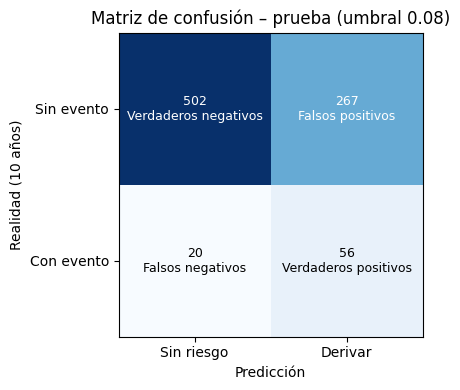

De 76 personas que tuvieron un evento coronario, el modelo detecta 56 y se le escapan 20.
Se derivan 323 de 845 personas (38%); 1 de cada 5.8 derivados tiene un evento.


In [11]:
vn, fp, fn, vp = confusion_matrix(y_test, pred_test).ravel()

fig, ax = plt.subplots(figsize=(4.8, 4))
mc = np.array([[vn, fp], [fn, vp]])
ax.imshow(mc, cmap="Blues")
etiquetas = [["Verdaderos negativos", "Falsos positivos"], ["Falsos negativos", "Verdaderos positivos"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{mc[i, j]}\n{etiquetas[i][j]}", ha="center", va="center",
                color="white" if mc[i, j] > mc.max() / 2 else "black", fontsize=9)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Sin riesgo", "Derivar"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Sin evento", "Con evento"])
ax.set_xlabel("Predicción"); ax.set_ylabel("Realidad (10 años)")
ax.set_title(f"Matriz de confusión – prueba (umbral {UMBRAL:.2f})")
plt.tight_layout(); plt.savefig("resultados/fig_matriz_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

print(f"De {vp + fn} personas que tuvieron un evento coronario, el modelo detecta {vp} y se le escapan {fn}.")
print(f"Se derivan {vp + fp} de {len(y_test)} personas ({(vp + fp) / len(y_test):.0%}); "
      f"1 de cada {(vp + fp) / vp:.1f} derivados tiene un evento.")

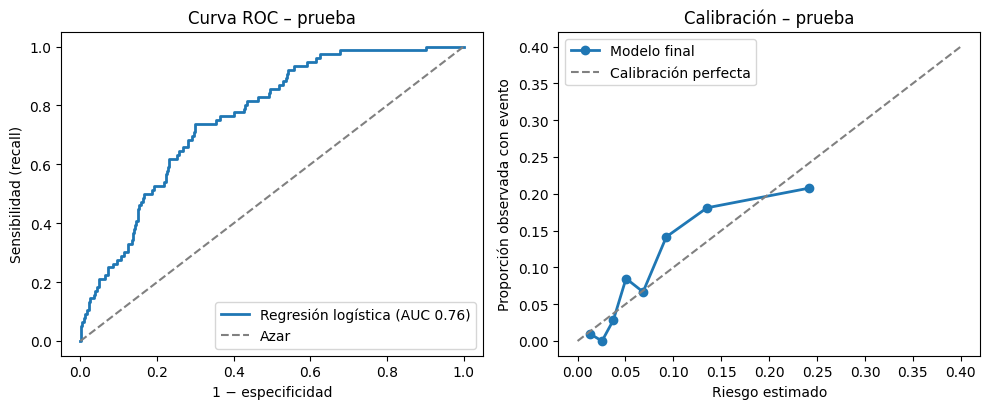

In [12]:
from sklearn.metrics import roc_curve
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, lw=2, label=f"Regresión logística (AUC {metricas_test['ROC-AUC']:.2f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Azar")
axes[0].set_xlabel("1 − especificidad"); axes[0].set_ylabel("Sensibilidad (recall)")
axes[0].set_title("Curva ROC – prueba"); axes[0].legend(loc="lower right")

obs, esp = calibration_curve(y_test, p_test, n_bins=8, strategy="quantile")
axes[1].plot(esp, obs, "o-", lw=2, label="Modelo final")
axes[1].plot([0, 0.4], [0, 0.4], "--", color="gray", label="Calibración perfecta")
axes[1].set_xlabel("Riesgo estimado"); axes[1].set_ylabel("Proporción observada con evento")
axes[1].set_title("Calibración – prueba"); axes[1].legend(loc="upper left")

plt.tight_layout(); plt.savefig("resultados/fig_roc_calibracion.png", dpi=150, bbox_inches="tight"); plt.show()

## Desempeño por sexo
El análisis ético del proyecto exige revisar si el modelo funciona igual para hombres y mujeres.

In [13]:
res = pd.DataFrame({"sexo": X_test["SEX"].map({1: "Hombres", 2: "Mujeres"}),
                    "y": y_test.values, "p": p_test, "pred": pred_test})

por_sexo = res.groupby("sexo").apply(lambda g: pd.Series({
    "Personas": len(g),
    "Casos": int(g.y.sum()),
    "Recall": recall_score(g.y, g.pred),
    "Precisión": precision_score(g.y, g.pred),
    "% derivado": g.pred.mean(),
    "ROC-AUC": roc_auc_score(g.y, g.p),
})).round(3)
por_sexo

,Personas,Casos,Recall,Precisión,% derivado,ROC-AUC
sexo,,,,,,
Hombres,355.0,36.0,0.861,0.145,0.603,0.710
Mujeres,490.0,40.0,0.625,0.229,0.222,0.817


El modelo detecta mejor los casos en hombres que en mujeres, porque a igual perfil les asigna más riesgo y los deriva más. En mujeres ordena mejor (ROC-AUC más alto), pero con este umbral único se le escapa una mayor proporción de casos. Es un hallazgo para el análisis ético: una alternativa es usar un umbral por sexo, y queda como propuesta de mejora.

Hay que considerar también que el conjunto de prueba tiene solo 36 casos en hombres y 40 en mujeres, así que estas cifras tienen bastante incertidumbre.

## Qué factores pesan en el modelo

In [14]:
lr = modelo_final.named_steps["modelo"]
odds = pd.DataFrame({
    "Variable": PRED,
    "Odds ratio": np.exp(lr.coef_[0]).round(2),
    "Por cada": ["+1 desviación estándar"] * len(CONT) + ["mujer vs. hombre", "fumador", "diabetes", "usa antihipertensivos"],
}).sort_values("Odds ratio", ascending=False)
odds

,Variable,Odds ratio,Por cada
0,AGE,1.54,+1 desviación estándar
10,DIABETES,1.43,diabetes
3,TOTCHOL,1.39,+1 desviación estándar
1,SYSBP,1.36,+1 desviación estándar
7,CIGPDAY,1.20,+1 desviación estándar
9,CURSMOKE,1.19,fumador
5,BMI,1.18,+1 desviación estándar
4,GLUCOSE,1.04,+1 desviación estándar
2,DIABP,1.03,+1 desviación estándar
6,HEARTRTE,0.90,+1 desviación estándar


Un odds ratio sobre 1 sube el riesgo; bajo 1 lo baja. En las continuas se compara una persona con otra que está una desviación estándar por encima.

## Guardar el modelo para la Parte 3

In [15]:
import joblib, sklearn

joblib.dump({
    "pipeline": modelo_final,       # preprocesamiento + regresión logística, ya entrenado
    "umbral": UMBRAL,               # sobre este riesgo se deriva
    "variables": PRED,              # columnas que espera, en este orden
    "metricas_prueba": metricas_test,
    "sklearn": sklearn.__version__,
}, "resultados/modelo_chd10a.pkl")

print("Guardado en:", os.path.abspath("resultados/modelo_chd10a.pkl"))
print("Archivos de la Parte 2:", os.listdir("resultados"))

Guardado en: /content/drive/.shortcut-targets-by-id/1Y-XrKLmj3y7vuHBzmQH9X-DvE-h6v7OV/Evalucion 3 y Examen/resultados/modelo_chd10a.pkl
Archivos de la Parte 2: ['experimentos.csv', 'fig_matriz_confusion.png', 'fig_roc_calibracion.png', 'modelo_chd10a.pkl', 'fig_prevalencia_tamizaje.png']


Para usarlo en la Parte 3:

```python
import joblib, pandas as pd
m = joblib.load("resultados/modelo_chd10a.pkl")
persona = pd.DataFrame([{...}])[m["variables"]]
riesgo = m["pipeline"].predict_proba(persona)[0, 1]
derivar = riesgo >= m["umbral"]
```

In [16]:
m = joblib.load("resultados/modelo_chd10a.pkl")
persona = pd.DataFrame([{"AGE": 60, "SEX": 1, "SYSBP": 150, "DIABP": 90, "TOTCHOL": 260,
                         "GLUCOSE": 100, "BMI": 28, "HEARTRTE": 75, "CURSMOKE": 1,
                         "CIGPDAY": 20, "DIABETES": 0, "BPMEDS": 0}])[m["variables"]]
riesgo = m["pipeline"].predict_proba(persona)[0, 1]
print(f"Riesgo a 10 años: {riesgo:.1%} → {'Derivar' if riesgo >= m['umbral'] else 'Sin riesgo'}")

Riesgo a 10 años: 30.1% → Derivar
